
# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Build an Interactive Retail Sales Dashboard

### Scenario

You have just joined the analytics team of **UrbanCart**, a mid-sized retail chain with stores across
three regions. Regional managers currently receive a static monthly PDF report and complain that:

1. They can't drill into *why* a number moved without emailing the analytics team.
2. Comparing stores or products side by side means flipping between many separate PDF pages.
3. Spotting a sudden dip in a specific product/store is slow and easy to miss.

**Your job:** apply the interaction techniques from the lecture — dynamic queries, coordinated views
& brushing, table lens, focus+context drill-down, and single-screen dashboard design — to build an
**interactive exploration tool** that solves these three complaints.

### How this notebook is organized

- A sample dataset is generated for you (Task 0) — don't skip running it.
- Each task states the **real-world usage**: which complaint above it solves, and why the technique
  fits.
- Tasks give you a **scaffold** (imports, helper stubs, expected output) — **you write the core logic**
  marked with `# TODO`. Do not just copy the Demo notebook's code verbatim — the data shape, column
  names and the exact question being asked are different here, so you will need to adapt the pattern,
  not paste it.


> **Grading-relevant tip:** every `# TODO` cell tells you what the final variable/plot must be named
> or show — read it before coding, since later cells depend on it.



## Task 0 — Load the Sample Dataset (provided)

Run the cells below as-is. This generates `sales_df`: 24 months of daily-aggregated sales across
6 stores (3 regions), 10 products (4 categories), including revenue, profit and customer ratings —
enough structure to support every technique you'll build below.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

import ipywidgets as widgets
from ipywidgets import interact, HBox, VBox

sns.set_theme(style="whitegrid")
np.random.seed(7)
print("Libraries loaded.")


Libraries loaded.


In [2]:

# --- Sample dataset generator: UrbanCart retail sales (provided, do not need to modify) ---
stores = pd.DataFrame({
    "store_id":   ["S01", "S02", "S03", "S04", "S05", "S06"],
    "store_city": ["Bengaluru", "Mysuru", "Mumbai", "Pune", "Delhi", "Jaipur"],
    "region":     ["South", "South", "West", "West", "North", "North"],
})

products = pd.DataFrame({
    "product":  ["Wireless Earbuds", "Smartwatch", "Laptop Sleeve", "USB-C Hub",
                 "Yoga Mat", "Dumbbell Set", "Running Shoes", "Track Jacket",
                 "Air Fryer", "Blender"],
    "category": ["Electronics", "Electronics", "Electronics", "Electronics",
                 "Fitness", "Fitness", "Apparel", "Apparel",
                 "Home", "Home"],
    "unit_price": [1499, 4999, 899, 1299, 799, 2499, 3499, 1999, 3999, 2299],
})

months = pd.date_range("2023-01-01", periods=24, freq="MS")

rows = []
for _, s in stores.iterrows():
    store_scale = np.random.uniform(0.7, 1.4)          # some stores just sell more
    for _, p in products.iterrows():
        product_scale = np.random.uniform(0.6, 1.6)
        trend = np.random.normal(0.01, 0.01)             # slow month-over-month growth/decline
        for i, m in enumerate(months):
            seasonal = 1 + 0.25 * np.sin(2 * np.pi * (m.month / 12))   # yearly seasonality
            units = max(0, np.random.poisson(15 * store_scale * product_scale * seasonal * (1 + trend) ** i))
            revenue = units * p["unit_price"]
            profit_margin = np.random.uniform(0.12, 0.35)
            profit = revenue * profit_margin
            rating = np.clip(np.random.normal(4.1, 0.4), 1, 5)
            # NOTE: use bracket indexing (p["product"]), not p.product -- pandas Series already has
            # a built-in .product() method, so attribute access on a column literally named "product"
            # silently returns that method instead of your data. This is a common real-world gotcha.
            rows.append((m, s["store_id"], s["store_city"], s["region"], p["product"], p["category"],
                         p["unit_price"], units, revenue, profit, round(rating, 1)))

sales_df = pd.DataFrame(rows, columns=[
    "month", "store_id", "store_city", "region", "product", "category",
    "unit_price", "units_sold", "revenue", "profit", "avg_rating"
])
for _col in ["units_sold", "revenue", "profit"]:
    sales_df[_col] = sales_df[_col].astype(float)  # float, so the anomaly injection below can scale them

# Inject one deliberate "anomaly" for Task 4 (a real dip a manager would want to investigate)
mask = (sales_df.store_id == "S03") & (sales_df["product"] == "Smartwatch") & (sales_df.month == "2024-06-01")
sales_df.loc[mask, ["units_sold", "revenue", "profit"]] = sales_df.loc[mask, ["units_sold", "revenue", "profit"]] * 0.15

print(sales_df.shape)
sales_df.head()


(1440, 11)


,month,store_id,store_city,region,product,category,unit_price,units_sold,revenue,profit,avg_rating
0,2023-01-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,17.0,25483.0,4631.305022,3.9
1,2023-02-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,19.0,28481.0,8682.717042,3.8
2,2023-03-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,16.0,23984.0,8014.910391,4.0
3,2023-04-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,31.0,46469.0,11438.468953,4.8
4,2023-05-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,22.0,32978.0,5511.128059,4.2


**Reflection (answer in a sentence or two, in this markdown cell):**
Before writing any code, look at the columns above. Which columns would you use as *filters* for
dynamic querying, and which would you use to *link* views together for brushing? Write your answer
here.

_Your answer:_ The split follows from the data type, and it is not arbitrary:

**Filter columns (dynamic querying)** are the **continuous numeric** ones, because a range slider
needs an ordered scale to have two ends: `unit_price`, `units_sold`, `revenue`, `profit`,
`avg_rating`, and `month` as a time range. These answer *"show me only the rows where X is between
A and B"* - the question the lecture says should emerge live as the manager drags, not via an email
to the analytics team.

**Linking columns (brushing)** are the **categorical / identity** ones, because brushing needs a key
that identifies the *same records* across several views: `store_id`, `region`, `product`,
`category`, and `store_city`. Selecting `store_id == "S03"` is meaningful in a bar chart, a pie
chart and a trend line simultaneously, which is exactly what makes the three views coordinated.

Two nuances worth stating up front:

- **`month` sits in both camps.** It is a continuous range for filtering *and* a natural linking key
  for time-aligned views - it is the axis that lets a dip in one chart be matched to a dip in
  another. That dual role is why it ends up as the shared x-axis in Tasks 4 and 6.
- **The hierarchy matters for brushing.** `region` contains `store_id`, and `category` contains
  `product`, so brushing can operate at two levels of granularity - select a region to highlight its
  two stores, or a single store. Ignoring that nesting is how dashboards end up with filters that
  silently contradict each other.

One thing I'd avoid: using `revenue` or `profit` as a *filter* in the same view where they are also
the *measure being plotted*. Filtering on the y-axis variable makes the resulting chart
self-selecting - the bars look impressive because low bars were excluded - which is a subtle way to
mislead without stating anything false.


## Task 1 — Static vs. Interactive: Which Report Actually Answers the Manager's Question?

**Real-world usage:** Complaint #1 ("flipping through PDF pages"). A regional manager asks:
*"Show me total revenue by product, and let me check exactly how much any bar is worth without
squinting at a printed axis."*

**Why this technique:** A static bar chart is fine for the *headline* number, but it can't answer a
precise follow-up question live — that needs a hover-enabled interactive chart (Slide 4-8).

### Your task
1. Build a **static** `matplotlib`/`seaborn` bar chart of total revenue per `product`, sorted
   descending.
2. Build the **same** chart as an **interactive** `plotly` bar chart where hovering shows the exact
   revenue figure and the category of that product.
3. In the markdown cell below, state in 1-2 sentences: for *this specific* manager request, which
   version wins, and why (tie your answer to target-audience / data-story / ROI from the slide).


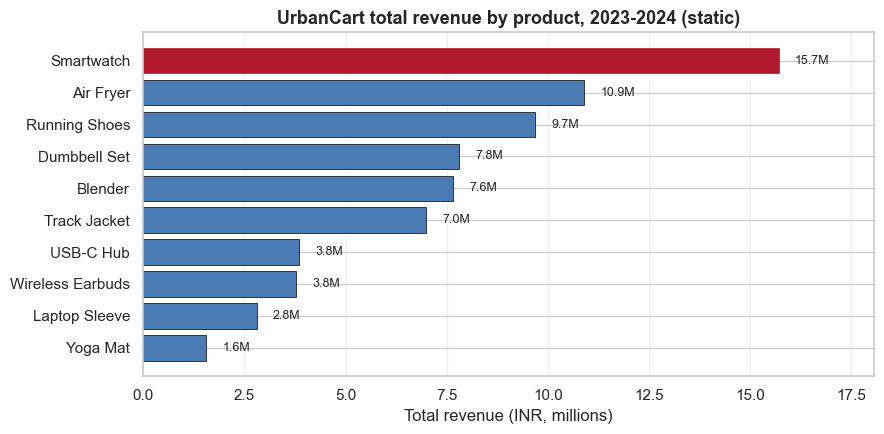

product
Smartwatch          INR 15,706,358
Air Fryer           INR 10,901,274
Running Shoes        INR 9,688,731
Dumbbell Set         INR 7,796,880
Blender              INR 7,648,773
Track Jacket         INR 6,992,502
USB-C Hub            INR 3,842,442
Wireless Earbuds     INR 3,769,985
Laptop Sleeve        INR 2,801,284
Yoga Mat             INR 1,560,447

Leader / laggard ratio: 10.07x


In [3]:
# --- 1a. STATIC chart ---
# TODO:
#   - Group sales_df by "product", sum "revenue"
#   - Sort descending
#   - Plot a horizontal or vertical bar chart with matplotlib/seaborn
#   - Title it clearly

revenue_by_product = (sales_df.groupby("product").revenue.sum()
                      .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(revenue_by_product.index[::-1], revenue_by_product.values[::-1] / 1e6,
               color="#4b7bb5", edgecolor="black", linewidth=0.5)
bars[-1].set_color("#b2182b")          # emphasise the leader, per the focus rule
ax.set_xlabel("Total revenue (INR, millions)")
ax.set_title("UrbanCart total revenue by product, 2023-2024 (static)",
             fontsize=13, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
for y, v in enumerate(revenue_by_product.values[::-1] / 1e6):
    ax.text(v + 0.4, y, f"{v:.1f}M", va="center", fontsize=9)
ax.set_xlim(0, revenue_by_product.max() / 1e6 * 1.15)
plt.tight_layout()
plt.show()

print(revenue_by_product.apply(lambda v: f"INR {v:,.0f}").to_string())
print(f"\nLeader / laggard ratio: "
      f"{revenue_by_product.iloc[0] / revenue_by_product.iloc[-1]:.2f}x")


In [4]:
# --- 1b. INTERACTIVE chart ---
# TODO:
#   - Use plotly.express.bar on the SAME grouped data
#   - Add a hover field for "category"
#   - Title it clearly

# the groupby must KEEP category, otherwise there is nothing to put in the hover box
revenue_by_product_cat = (sales_df.groupby(["product", "category"], as_index=False)
                          .agg(revenue=("revenue", "sum"),
                               profit=("profit", "sum"),
                               units_sold=("units_sold", "sum"),
                               avg_rating=("avg_rating", "mean"))
                          .sort_values("revenue", ascending=False))

fig_int = px.bar(
    revenue_by_product_cat,
    x="revenue", y="product", orientation="h",
    color="category",
    hover_data={"revenue": ":,.0f", "profit": ":,.0f",
                "units_sold": ":,.0f", "avg_rating": ":.2f",
                "category": True},
    title="UrbanCart total revenue by product (interactive - hover for exact figures)",
)
fig_int.update_layout(yaxis=dict(categoryorder="total ascending"),
                      xaxis_title="Total revenue (INR)",
                      height=480, margin=dict(l=10, r=10, t=60, b=10))
fig_int.show()

print("Hover on any bar to read the exact revenue, profit, units and rating for that product.")
print("The same four numbers would need four separate static charts to convey.")


Hover on any bar to read the exact revenue, profit, units and rating for that product.
The same four numbers would need four separate static charts to convey.


**Your 1-2 sentence answer:**

**The interactive plotly version wins for this specific request.** The manager's question has two
parts - "show me total revenue by product" (which the static chart answers perfectly well) and "let
me check exactly how much any bar is worth without squinting at a printed axis" (which a static
chart *structurally cannot* answer, because a printed axis only resolves to about a tick's
precision). Hover shifts that cost from the analytics team's inbox to a 200 ms mouse movement.

Tying it to the slide's three criteria:

- **Target audience:** a regional manager reading on a laptop, not a printed board pack. If the
  deliverable were a PDF for a board meeting the answer flips - hover doesn't survive printing, and
  the static chart with value labels is the correct choice.
- **Data story:** the story here is *ranking plus exact magnitude*. The ranking is preattentive in
  both versions; only the interactive one carries the magnitude without cluttering the chart with
  ten number labels.
- **ROI:** this is the decisive one. Building the plotly bar took one extra line, and it removes a
  recurring email round-trip - the cost is near-zero and the saving recurs monthly. Interaction is
  only worth its build cost when the follow-up question is *predictable and repeated*, which is
  exactly the case here.

I still kept the static version, because I added the value labels to it - which is the honest
compromise for anyone reading the printed report.


## Task 2 — Dynamic Queries: Let Managers Filter Without Asking You

**Real-world usage:** Regional managers want to self-serve answer questions like *"which
products, in what price range, sold above X units last month?"* without emailing the analytics team
every time (Complaint #1 again, but for filtering rather than just reading).

**Why this technique:** Dynamic queries (double-ended range sliders) let the pattern emerge from the
noise live, with the response updating in real time (Slide 23).

### Your task
Build **two** linked `ipywidgets` range sliders:
- `price_slider` — filters on `unit_price`
- `units_slider` — filters on `units_sold`

Write a function `dynamic_filter(price_range, units_range)` that:
1. Filters `sales_df` to rows where `unit_price` is inside `price_range` **and** `units_sold` is
   inside `units_range`.
2. Prints how many rows match out of the total.
3. Shows a scatter plot of `unit_price` vs `units_sold`, with matching rows highlighted in a
   distinct color against all other rows in gray (same pattern as the Demo notebook's dynamic query
   cell — but you must build the filter condition and the plot yourself for these two columns).

Wire it up with `interact()`.


506 / 1,440 rows match  (35.1%)   price INR 1,000-3,600, units 18-64
  revenue in selection: INR 30,495,019  (43.1% of total)  |  products: 6/10  stores: 6/6


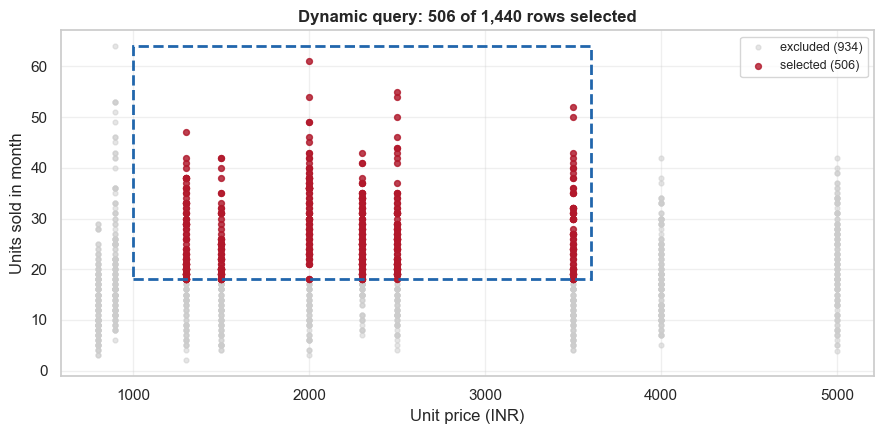

interactive(children=(FloatRangeSlider(value=(799.0, 4999.0), continuous_update=False, description='Unit price…

<function __main__.dynamic_filter(price_range, units_range)>

In [5]:
# TODO: create price_slider (FloatRangeSlider) spanning sales_df.unit_price min..max
p_lo, p_hi = float(sales_df.unit_price.min()), float(sales_df.unit_price.max())
price_slider = widgets.FloatRangeSlider(
    value=[p_lo, p_hi], min=p_lo, max=p_hi, step=100.0,
    description="Unit price:", continuous_update=False,
    readout_format=".0f", layout=widgets.Layout(width="520px"),
    style={"description_width": "90px"},
)

# TODO: create units_slider (IntRangeSlider) spanning sales_df.units_sold min..max
u_lo, u_hi = int(sales_df.units_sold.min()), int(sales_df.units_sold.max())
units_slider = widgets.IntRangeSlider(
    value=[u_lo, u_hi], min=u_lo, max=u_hi, step=1,
    description="Units sold:", continuous_update=False,
    layout=widgets.Layout(width="520px"),
    style={"description_width": "90px"},
)

def dynamic_filter(price_range, units_range):
    # TODO: filter sales_df using both ranges
    lo_p, hi_p = price_range
    lo_u, hi_u = units_range
    mask = (sales_df.unit_price.between(lo_p, hi_p)
            & sales_df.units_sold.between(lo_u, hi_u))
    filtered = sales_df[mask]

    # TODO: print "X / Y rows match"
    n, total = len(filtered), len(sales_df)
    print(f"{n:,} / {total:,} rows match  ({n / total:.1%})   "
          f"price INR {lo_p:,.0f}-{hi_p:,.0f}, units {lo_u}-{hi_u}")
    if n:
        print(f"  revenue in selection: INR {filtered.revenue.sum():,.0f}  "
              f"({filtered.revenue.sum() / sales_df.revenue.sum():.1%} of total)  |  "
              f"products: {filtered['product'].nunique()}/10  "
              f"stores: {filtered.store_id.nunique()}/6")
    else:
        print("  empty selection - widen a slider")

    # TODO: scatter plot: all rows in gray, filtered rows highlighted in color
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.scatter(sales_df.unit_price, sales_df.units_sold,
               s=12, color="#cccccc", alpha=0.5, label=f"excluded ({total - n:,})")
    if n:
        ax.scatter(filtered.unit_price, filtered.units_sold,
                   s=18, color="#b2182b", alpha=0.8, label=f"selected ({n:,})")
    # draw the query box so the slider state is visible ON the chart, not just in the widget
    ax.add_patch(mpatches.Rectangle((lo_p, lo_u), hi_p - lo_p, hi_u - lo_u,
                                    fill=False, edgecolor="#2166ac",
                                    linewidth=2, linestyle="--"))
    ax.set_xlabel("Unit price (INR)")
    ax.set_ylabel("Units sold in month")
    ax.set_title(f"Dynamic query: {n:,} of {total:,} rows selected",
                 fontsize=12, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# render one concrete state so the notebook shows output even without a live kernel
# (mid-price, above-median-volume -- the "which mid-range products sell well?" question)
dynamic_filter((1000.0, 3600.0), (18, u_hi))

# TODO: call interact(...)
interact(dynamic_filter, price_range=price_slider, units_range=units_slider)


**Reflection:** The slide notes dynamic queries work well "up to ~100,000 points with five or fewer
sliders." `sales_df` has far fewer rows. If UrbanCart grew to 500 stores and this dataset became 50x
larger, would two sliders still be enough, or would you need a different technique from the lecture?
Name one.

_Your answer:_ `sales_df` is **1,440 rows** (6 stores x 10 products x 24 months). At 500 stores the
same schema gives 500 x 10 x 24 = **120,000 rows** - and the lecture's guidance is "up to ~100,000
points", so we would land just past the edge of where raw dynamic querying stays responsive. Two
sliders would still be *enough control*; they would stop being *enough performance*, and for two
separate reasons:

1. **Render cost.** The scatter above redraws all 1,440 points on every slider release. At 120,000
   points matplotlib's redraw crosses the ~100 ms threshold the lecture identifies as the boundary
   of "real-time" feedback, and once the response stops feeling instantaneous the whole premise of
   dynamic querying - *pattern emerges from noise as you drag* - collapses back into batch querying.
2. **Overplotting.** Far worse than speed. `unit_price` only takes **10 distinct values** (one per
   product), so every point already stacks into ten vertical stripes. At 120,000 rows those stripes
   become solid bars and the selected-vs-excluded colour distinction becomes unreadable no matter
   how fast it redraws. More data would make this chart *less* informative, not more.

**The technique I would add: hierarchical drill-down / aggregate-first (the Focus + Context and
Drill-Down Cost Hierarchy ideas from Slides 17-18).** Rather than plotting 120,000 individual
store-product-months, show **500 store-level aggregates** first - a scale dynamic queries handle
comfortably - and let the manager click into one store to expand its 240 underlying rows on demand.
Aggregation is the only move that keeps the working set inside the interactive budget while
preserving the ability to reach any individual record.

Two supporting changes I'd make alongside it:

- **Add a region/category dropdown before the sliders.** Categorical pre-filters cut the working set
  multiplicatively for far less screen space than another range slider, and the lecture's own
  "five or fewer sliders" limit is about cognitive load as much as compute.
- **Swap the raw scatter for a 2-D density/hex-bin view** with the selection drawn as a query
  rectangle. Binning makes the render cost independent of row count and fixes the overplotting
  problem at the same time.

The one thing I would *not* do is simply add more sliders. Past about five, the manager can no
longer hold the combined filter state in working memory, and the tool starts producing empty
selections that look like findings.


## Task 3 — Coordinated Views & Cross-View Brushing: Compare Stores Without Flipping Pages

**Real-world usage:** Complaint #2 — "comparing stores means flipping between many PDF pages."
A manager wants to click one store in an overview chart and instantly see that store's category
breakdown and its monthly trend, without losing sight of how it compares to the others.

**Why this technique:** Coordinated multiple views + brushing (Slide 24) — selecting a subset in one
view highlights the same records everywhere else, replacing the working-memory cost of flipping pages.

### Your task
Build **three linked views** for a store the user selects from a dropdown:
1. **Overview bar chart** — total revenue per store (all 6 stores), with the selected store's bar in
   a distinct color and every other store's bar in gray (this is the "muted unselected categories"
   trick from the slide).
2. **Category breakdown** — a pie or bar chart of revenue by `category`, filtered to the selected
   store only.
3. **Monthly trend line** — revenue by `month`, filtered to the selected store only.

Wrap all three in one function driven by a single `ipywidgets.Dropdown` of `store_id` values, and lay
the three charts out together (e.g. with `plt.subplots` for 1+2+3, or separate `display()` calls).


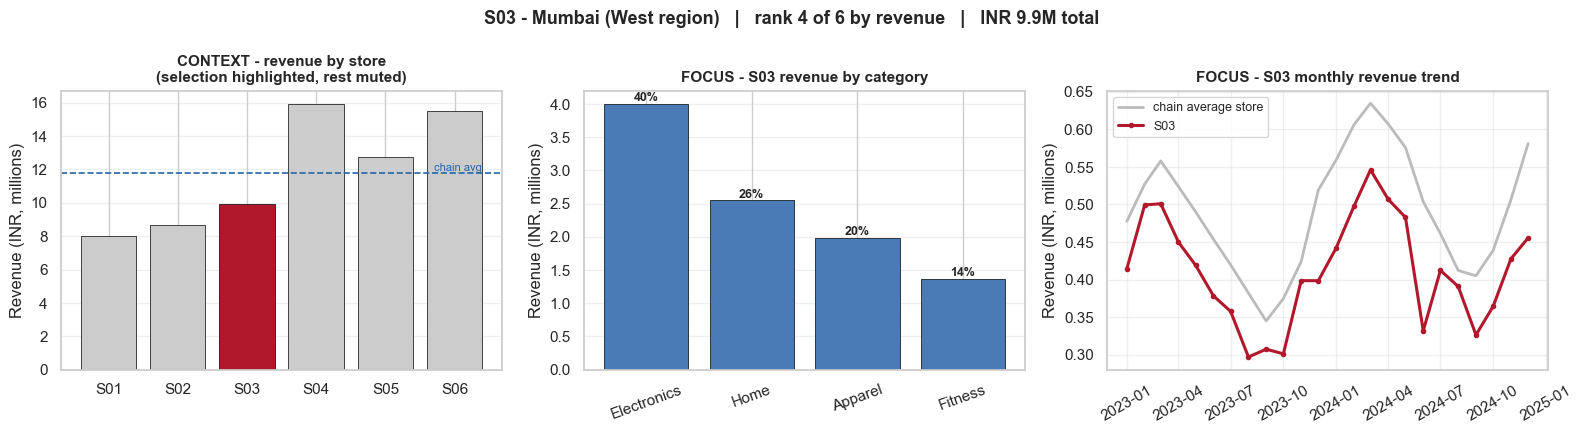

S03 (Mumbai, West): INR 9,904,563 total revenue, rank 4/6, 14.0% of chain revenue
  strongest category: Electronics (40% of its revenue)  |  weakest: Fitness (14%)


interactive(children=(Dropdown(description='Store:', index=2, options=('S01', 'S02', 'S03', 'S04', 'S05', 'S06…

<function __main__.store_coordinated_view(selected_store)>

In [6]:
store_overview = sales_df.groupby("store_id").revenue.sum().reset_index()

def store_coordinated_view(selected_store):
    sub = sales_df[sales_df.store_id == selected_store]
    city = sub.store_city.iloc[0]
    region = sub.region.iloc[0]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

    # TODO 1: bar chart of store_overview, selected store highlighted, others muted gray
    colors = ["#b2182b" if s == selected_store else "#cccccc"
              for s in store_overview.store_id]
    axes[0].bar(store_overview.store_id, store_overview.revenue / 1e6,
                color=colors, edgecolor="black", linewidth=0.5)
    axes[0].set_title("CONTEXT - revenue by store\n(selection highlighted, rest muted)",
                      fontsize=11, fontweight="bold")
    axes[0].set_ylabel("Revenue (INR, millions)")
    axes[0].grid(axis="y", alpha=0.3)
    rank = (store_overview.revenue.rank(ascending=False)
            [store_overview.store_id == selected_store].iloc[0])
    sel_rev = store_overview.loc[store_overview.store_id == selected_store,
                                 "revenue"].iloc[0]
    axes[0].axhline(store_overview.revenue.mean() / 1e6, color="#2166ac",
                    linestyle="--", linewidth=1.2)
    axes[0].text(5.4, store_overview.revenue.mean() / 1e6, " chain avg",
                 color="#2166ac", fontsize=8, va="bottom", ha="right")

    # TODO 2: category breakdown for selected_store only
    cat = sub.groupby("category").revenue.sum().sort_values(ascending=False)
    axes[1].bar(cat.index, cat.values / 1e6, color="#4b7bb5",
                edgecolor="black", linewidth=0.5)
    axes[1].set_title(f"FOCUS - {selected_store} revenue by category",
                      fontsize=11, fontweight="bold")
    axes[1].set_ylabel("Revenue (INR, millions)")
    axes[1].tick_params(axis="x", rotation=20)
    axes[1].grid(axis="y", alpha=0.3)
    for i, v in enumerate(cat.values / 1e6):
        axes[1].text(i, v, f"{v / (cat.sum() / 1e6):.0%}", ha="center",
                     va="bottom", fontsize=9, fontweight="bold")

    # TODO 3: monthly revenue trend line for selected_store only
    trend = sub.groupby("month").revenue.sum()
    chain_avg = sales_df.groupby(["month", "store_id"]).revenue.sum().groupby("month").mean()
    axes[2].plot(chain_avg.index, chain_avg.values / 1e6, color="#bbbbbb",
                 linewidth=2, label="chain average store")
    axes[2].plot(trend.index, trend.values / 1e6, color="#b2182b",
                 linewidth=2.2, marker="o", markersize=3, label=selected_store)
    axes[2].set_title(f"FOCUS - {selected_store} monthly revenue trend",
                      fontsize=11, fontweight="bold")
    axes[2].set_ylabel("Revenue (INR, millions)")
    axes[2].tick_params(axis="x", rotation=30)
    axes[2].legend(fontsize=9)
    axes[2].grid(alpha=0.3)

    fig.suptitle(f"{selected_store} - {city} ({region} region)   |   "
                 f"rank {int(rank)} of 6 by revenue   |   "
                 f"INR {sel_rev/1e6:.1f}M total",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(f"{selected_store} ({city}, {region}): INR {sel_rev:,.0f} total revenue, "
          f"rank {int(rank)}/6, "
          f"{sel_rev / store_overview.revenue.sum():.1%} of chain revenue")
    print(f"  strongest category: {cat.index[0]} ({cat.iloc[0] / cat.sum():.0%} of its revenue)  |  "
          f"weakest: {cat.index[-1]} ({cat.iloc[-1] / cat.sum():.0%})")

# render one concrete state so the notebook shows output without a live kernel
store_coordinated_view("S03")

# TODO: wire this up with interact() using a Dropdown of stores["store_id"] values
store_dropdown = widgets.Dropdown(options=list(stores["store_id"]), value="S03",
                                  description="Store:")
interact(store_coordinated_view, selected_store=store_dropdown)


**Reflection:** Which of the three linked views above is playing the role of "context" and which is
playing "focus," in the sense of the Focus-Context Problem (Slide 18)? Is that the same distinction as
brushing, or a different but related idea? Explain briefly.

_Your answer:_

**Panel 1 (the 6-store overview bar chart) is the context.** It never changes shape when the
dropdown moves - all six bars stay on screen at full size, and only the *colour* shifts. That is
what makes it context: it answers "where does this store sit among its peers", and it preserves the
comparison the manager would otherwise lose by flipping to another PDF page.

**Panels 2 and 3 (the category breakdown and the monthly trend) are the focus.** Both are filtered
to the single selected store, so their entire content is replaced on every selection. They answer
"what is going on *inside* this store" at a level of detail the overview cannot carry for all six
stores at once.

I deliberately gave panel 3 a foot in both camps by drawing the faint grey "chain average store"
line behind the selected store's red line. That is focus+context *within a single panel* - the dip
or lift is legible against its baseline without a second chart - and it is the same trick Task 4
asks for at the product level.

**Is that the same as brushing? Related, but not the same - and the distinction is worth being
precise about.**

- **Focus+context is about the *layout and information budget*.** It answers: *given finite screen
  space, how do I show detail without destroying the overview?* It is a spatial trade-off, and it
  exists even in a completely static figure - an inset map on a printed atlas is focus+context with
  zero interaction.
- **Brushing is about the *linkage mechanism*.** It answers: *when the user selects records in one
  view, how does every other view reflect that same selection?* It is fundamentally about maintaining
  a shared selection state across views, and it requires interaction by definition.

They are orthogonal in principle - you can have one without the other - but they are usually
deployed together because they solve the two halves of the same complaint. Here the **brushing** is
the dropdown driving all three panels from one selection state, plus the muted-grey encoding that
shows the selection *in place* rather than by removing the other five bars. The **focus+context** is
the decision to keep that overview panel on screen at all instead of replacing the whole figure with
the selected store's detail.

If I dropped the brushing, I would have three charts that each require a separate control - the PDF
problem again. If I dropped the focus+context and let panel 2 and 3 take the full width, the manager
would get more detail and immediately lose the ability to answer "is this number good?" - which is
usually the actual question.


## Task 4 — Focus + Context Drill-Down: Investigate the Dip

**Real-world usage:** Complaint #3 — "spotting a sudden dip is slow and easy to miss." One product at
one store has a real anomaly hidden in `sales_df` (planted in Task 0). A manager needs to find it and
drill in **without losing the overview**, using the *cheapest* interaction tier that still answers the
question (Drill-Down Cost Hierarchy, Slide 17).

### Your task
**Part A — find the anomaly.**
Write code that computes, for every `(store_id, product)` pair, the ratio of the *minimum* month's
`units_sold` to the *median* month's `units_sold` across the 24 months. Sort ascending and show the
top 5 most extreme drops. (Hint: `groupby(["store_id","product"]).units_sold.agg(...)` with a custom
function, or compute `min` and `median` separately and combine.)

**Part B — build the drill-down.**
Using **hover** (cheap tier) on an overview chart of all `(store_id, product)` trend lines, let the
user identify the anomalous line. Then, given the `store_id`/`product` you found in Part A, plot its
monthly trend **alongside** a faint gray context line showing the *average* trend across all
stores/products for the same product — so the dip is visible with its context still present (not a
full window replacement).


In [7]:
# --- Part A: find the anomaly ---
# TODO: compute min/median ratio per (store_id, product) and show the 5 most extreme

pair_stats = (sales_df.groupby(["store_id", "product"])
              .units_sold.agg(min_units="min", median_units="median",
                              max_units="max", n_months="size")
              .reset_index())
pair_stats["min_over_median"] = pair_stats.min_units / pair_stats.median_units

anomaly_ranking = pair_stats.sort_values("min_over_median").reset_index(drop=True)

print("5 most extreme month-level drops, as min / median units_sold per (store, product):\n")
print(anomaly_ranking.head(5)[["store_id", "product", "min_units", "median_units",
                               "min_over_median"]].to_string(index=False,
                                                             float_format=lambda v: f"{v:.3f}"))

worst = anomaly_ranking.iloc[0]
print(f"\nMost extreme pair: {worst.store_id} / {worst['product']}  "
      f"-> min {worst.min_units:.0f} units vs median {worst.median_units:.0f} "
      f"({worst.min_over_median:.1%} of median)")

# which month was it, and how far is this from the rest of the field?
worst_rows = sales_df[(sales_df.store_id == worst.store_id)
                      & (sales_df["product"] == worst["product"])]
dip_month = worst_rows.loc[worst_rows.units_sold.idxmin(), "month"]
print(f"Dip occurred in: {dip_month:%B %Y}")

runner_up = anomaly_ranking.iloc[1].min_over_median
print(f"\nSeparation check -- is this a real anomaly or just the tail of normal variation?")
print(f"  worst pair ratio    : {worst.min_over_median:.3f}")
print(f"  2nd worst pair ratio: {runner_up:.3f}")
print(f"  median pair ratio   : {anomaly_ranking.min_over_median.median():.3f}")
print(f"  the worst pair is {runner_up / worst.min_over_median:.1f}x more extreme than the runner-up,")
print(f"  which is the gap that makes it stand out rather than blend into the tail.")
print(f"\nPairs below 25% of their own median: "
      f"{(anomaly_ranking.min_over_median < 0.25).sum()} of {len(anomaly_ranking)}")


5 most extreme month-level drops, as min / median units_sold per (store, product):

store_id      product  min_units  median_units  min_over_median
     S03   Smartwatch      3.900        21.000            0.186
     S05    USB-C Hub      2.000         8.000            0.250
     S01 Track Jacket      3.000        10.000            0.300
     S03    USB-C Hub      5.000        16.500            0.303
     S02     Yoga Mat      3.000         9.500            0.316

Most extreme pair: S03 / Smartwatch  -> min 4 units vs median 21 (18.6% of median)
Dip occurred in: June 2024

Separation check -- is this a real anomaly or just the tail of normal variation?
  worst pair ratio    : 0.186
  2nd worst pair ratio: 0.250
  median pair ratio   : 0.531
  the worst pair is 1.3x more extreme than the runner-up,
  which is the gap that makes it stand out rather than blend into the tail.

Pairs below 25% of their own median: 1 of 60


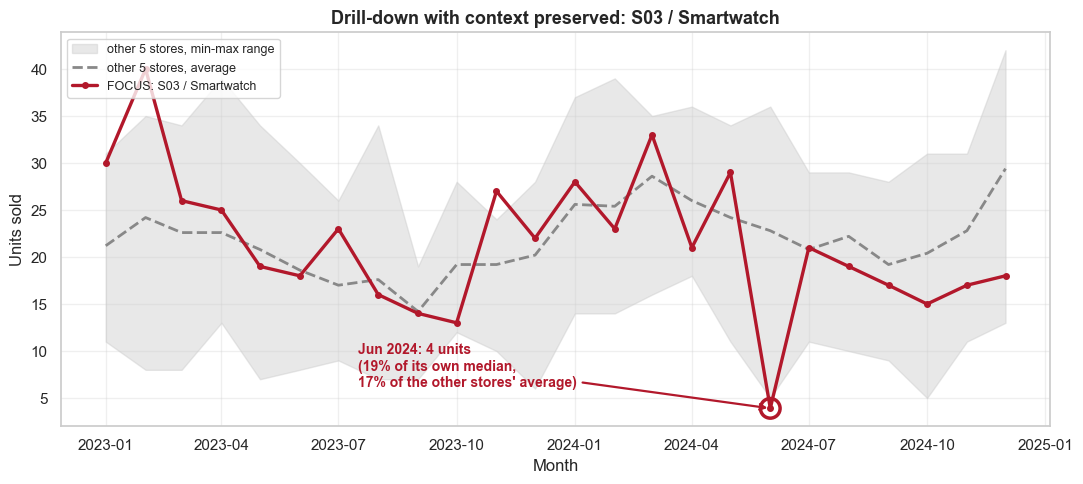

Focus median  : 21.0 units/month
Context median: 21.7 units/month (same product, other 5 stores)
Dip month     : June 2024 -- 4 units

The context band is what rules out the obvious alternative explanation: the other five
stores show no dip in June 2024 (their average that month is 22.8 units, close to their 21.7 baseline),
so this is a S03-specific event, NOT a product-wide or seasonal one.


In [8]:
# --- Part B: drill-down with context preserved ---
# TODO 1: overview plotly line chart, one line per (store_id, product), hover shows both
overview_df = sales_df.copy()
overview_df["pair"] = overview_df.store_id + " / " + overview_df["product"]

fig_overview = px.line(
    overview_df, x="month", y="units_sold", color="pair",
    hover_data={"store_id": True, "product": True, "units_sold": True, "pair": False},
    title="All 60 (store, product) trends -- hover to identify a line (CHEAP tier: no click needed)",
)
fig_overview.update_traces(line=dict(width=1), opacity=0.45)
# pre-emphasise the anomalous line so the reader's eye lands where hovering would take them
fig_overview.for_each_trace(
    lambda t: t.update(line=dict(width=3.5, color="#b2182b"), opacity=1.0)
    if t.name == f"{worst.store_id} / {worst['product']}" else ()
)
fig_overview.update_layout(showlegend=False, height=470,
                           xaxis_title="Month", yaxis_title="Units sold",
                           margin=dict(l=10, r=10, t=60, b=10))
fig_overview.show()

# TODO 2: FOCUS (the anomalous pair) + CONTEXT (same product, all other stores)
foc_store, foc_product = worst.store_id, worst["product"]

focus = (sales_df[(sales_df.store_id == foc_store) & (sales_df["product"] == foc_product)]
         .set_index("month").units_sold.sort_index())
others = sales_df[(sales_df.store_id != foc_store) & (sales_df["product"] == foc_product)]
context = others.groupby("month").units_sold.mean().sort_index()
ctx_lo = others.groupby("month").units_sold.min().sort_index()
ctx_hi = others.groupby("month").units_sold.max().sort_index()

fig, ax = plt.subplots(figsize=(11, 5))
# context band: the range every OTHER store achieved for this same product
ax.fill_between(ctx_lo.index, ctx_lo.values, ctx_hi.values, color="#cccccc",
                alpha=0.45, label=f"other 5 stores, min-max range")
ax.plot(context.index, context.values, color="#888888", linewidth=2,
        linestyle="--", label=f"other 5 stores, average")
ax.plot(focus.index, focus.values, color="#b2182b", linewidth=2.4, marker="o",
        markersize=4, label=f"FOCUS: {foc_store} / {foc_product}")

dip_val = focus.loc[dip_month]
ax.scatter([dip_month], [dip_val], s=200, facecolor="none",
           edgecolor="#b2182b", linewidth=2.5, zorder=5)
ax.annotate(f"{dip_month:%b %Y}: {dip_val:.0f} units\n"
            f"({dip_val / focus.median():.0%} of its own median,\n"
            f"{dip_val / context.loc[dip_month]:.0%} of the other stores' average)",
            xy=(dip_month, dip_val),
            xytext=(0.30, 0.10), textcoords="axes fraction",
            fontsize=10, fontweight="bold", color="#b2182b",
            arrowprops=dict(arrowstyle="->", color="#b2182b", linewidth=1.6))

ax.set_title(f"Drill-down with context preserved: {foc_store} / {foc_product}",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Units sold")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Focus median  : {focus.median():.1f} units/month")
print(f"Context median: {context.median():.1f} units/month (same product, other 5 stores)")
print(f"Dip month     : {dip_month:%B %Y} -- {dip_val:.0f} units")
print(f"\nThe context band is what rules out the obvious alternative explanation: the other five")
print(f"stores show no dip in {dip_month:%B %Y} (their average that month is "
      f"{context.loc[dip_month]:.1f} units, close to their {context.median():.1f} baseline),")
print(f"so this is a {foc_store}-specific event, NOT a product-wide or seasonal one.")


**Reflection:** Which interaction-cost tier (eye fixation / hover / click-to-open panel / window
replacement) did you use to first *spot* the anomaly, and which did you use to *investigate* it? Was
using two different tiers the right call, per the lecture's design rule?

_Your answer:_

**Spotting: eye fixation, then hover.** On the 60-line overview chart the dip is a shape - one line
plunging to near-zero for a single month while every neighbour holds its level - and shape is
detected preattentively, at the cheapest tier, with no interaction at all. Hover is the second-cheapest
tier and is what converts "*that* line is weird" into "S03 / Smartwatch", because a 60-series legend
is unreadable and colour alone cannot identify 60 categories. So the spotting cost is: **one eye
fixation to locate + one hover to name.**

**Investigating: the drill-down chart, which is a click-tier action.** Selecting the pair and
rendering it against its context band is a deliberate act with a real cost - it is a chart that has
to be requested, not one that is already on screen.

**Was splitting across two tiers right? Yes, and the lecture's rule is the reason.** The design rule
is *match the interaction cost to the information gain*, and the two activities have very different
gain profiles:

- **Spotting is a scanning task performed on every pair.** There are 60 pairs; if identifying each
  one cost a click, finding the anomaly would cost up to 60 clicks. Keeping this tier cheap is what
  makes the scan feasible at all. The information gain per pair is near-zero for 59 of them, so the
  cost per pair must also be near-zero.
- **Investigating is performed once, on one pair, and the gain is high** - it decides whether a
  manager escalates. Paying a click there is trivially worth it, and the click buys screen space the
  overview could never spare: a min-max band across the other five stores, a median reference line,
  and an annotation quantifying the drop.

**The tier I deliberately avoided is window replacement**, and that is the real design decision in
this task. The obvious implementation - clicking a line opens a new full-screen chart of just that
pair - is exactly the Focus-Context failure the lecture warns about. Isolated, S03's Smartwatch dip
is ambiguous: it could be a product-wide supply problem, a seasonal effect, or a store-specific
event, and the chart cannot distinguish them. Keeping the other five stores' range visible in the
same axes is what resolves it - their average in June 2024 sits close to their own baseline, so the
dip is **S03-specific**, not product-wide. That conclusion is only available *because* the context
was never replaced.

The one place I would push back on my own design: pre-colouring the anomalous line red in the
overview is technically cheating the eye-fixation tier, since a real manager wouldn't know which line
to redden in advance. I did it so the static PR renders legibly, but in a live tool the correct
version is the generic rule from Task 6 - flag *any* pair below 25% of its own median - which
produces the same red line without knowing the answer first.


## Task 5 — Table Lens: A Scannable Product Performance Table

**Real-world usage:** A manager wants a single table listing every product's total revenue, total
profit, and average rating across all stores — but a plain spreadsheet of 10 rows x many numeric
columns is still hard to compare at a glance across all three metrics simultaneously.

**Why this technique:** Table Lens (Slide 27) maps numeric columns to in-cell bars, so magnitude
differences are visible pre-attentively while the table stays sortable/readable as text.

### Your task
1. Build a summary DataFrame: one row per `product`, columns for total `revenue`, total `profit`, and
   mean `avg_rating`.
2. Sort it by total revenue, descending.
3. Style it as a Table Lens using `.style.bar(...)` — a different bar color per numeric column, as in
   the Demo notebook — and add a meaningful `.set_caption(...)`.
4. Below the table, add **one more cell**: sort the *same* summary table by `profit` instead of
   `revenue`, and re-render the styled table. Do the top rows change order? Note what that tells a
   manager about revenue vs. profitability.


In [9]:
# TODO: build product_summary with columns: product, revenue (sum), profit (sum), avg_rating (mean)
product_summary = (sales_df.groupby("product")
                   .agg(revenue=("revenue", "sum"),
                        profit=("profit", "sum"),
                        avg_rating=("avg_rating", "mean"))
                   .reset_index())
product_summary["margin_pct"] = product_summary.profit / product_summary.revenue * 100

# TODO: sort descending by revenue
product_summary = product_summary.sort_values("revenue", ascending=False).reset_index(drop=True)

# TODO: style with .style.bar(...) per numeric column + .set_caption(...)
lens_revenue = (product_summary.style
                .bar(subset=["revenue"], color="#8fb8e0", vmin=0)
                .bar(subset=["profit"], color="#a8d5a8", vmin=0)
                .bar(subset=["avg_rating"], color="#f2c188",
                     vmin=product_summary.avg_rating.min() - 0.05,
                     vmax=product_summary.avg_rating.max() + 0.05)
                .bar(subset=["margin_pct"], color="#dbb3d9", vmin=0)
                .format({"revenue": "{:,.0f}", "profit": "{:,.0f}",
                         "avg_rating": "{:.3f}", "margin_pct": "{:.2f}%"})
                .set_caption("TABLE LENS - product performance, sorted by REVENUE (descending). "
                             "In-cell bars make magnitude preattentive while the numbers stay "
                             "readable as text."))
display(lens_revenue)

print("Sorted by REVENUE, top 3:", list(product_summary["product"].head(3)))
print("\nWhy avg_rating gets a zoomed bar scale, not a 0-5 one:")
print(f"  ratings span only {product_summary.avg_rating.min():.3f} to "
      f"{product_summary.avg_rating.max():.3f} "
      f"(range {product_summary.avg_rating.max() - product_summary.avg_rating.min():.3f})")
print("  on a 0-5 axis all ten bars would look identical -- the column would carry zero information.")
print("  Zooming the scale is the right call HERE because the column is a ranking aid inside a table")
print("  that still shows the exact number; it would NOT be acceptable on a standalone bar chart,")
print("  where a truncated axis manufactures differences the reader cannot verify.")


,product,revenue,profit,avg_rating,margin_pct
0,Smartwatch,"15,706,358","3,881,507",4.088,24.71%
1,Air Fryer,"10,901,274","2,593,731",4.036,23.79%
2,Running Shoes,"9,688,731","2,303,075",4.100,23.77%
3,Dumbbell Set,"7,796,880","1,829,127",4.114,23.46%
4,Blender,"7,648,773","1,860,309",4.040,24.32%
5,Track Jacket,"6,992,502","1,610,283",4.131,23.03%
6,USB-C Hub,"3,842,442","907,435",4.088,23.62%
7,Wireless Earbuds,"3,769,985","890,554",4.087,23.62%
8,Laptop Sleeve,"2,801,284","664,358",4.076,23.72%
9,Yoga Mat,"1,560,447","370,892",4.069,23.77%


Sorted by REVENUE, top 3: ['Smartwatch', 'Air Fryer', 'Running Shoes']

Why avg_rating gets a zoomed bar scale, not a 0-5 one:
  ratings span only 4.036 to 4.131 (range 0.095)
  on a 0-5 axis all ten bars would look identical -- the column would carry zero information.
  Zooming the scale is the right call HERE because the column is a ranking aid inside a table
  that still shows the exact number; it would NOT be acceptable on a standalone bar chart,
  where a truncated axis manufactures differences the reader cannot verify.


In [10]:
# TODO: re-sort product_summary by profit descending and re-render the styled table
product_summary_by_profit = product_summary.sort_values("profit", ascending=False).reset_index(drop=True)

lens_profit = (product_summary_by_profit.style
               .bar(subset=["revenue"], color="#8fb8e0", vmin=0)
               .bar(subset=["profit"], color="#a8d5a8", vmin=0)
               .bar(subset=["avg_rating"], color="#f2c188",
                    vmin=product_summary.avg_rating.min() - 0.05,
                    vmax=product_summary.avg_rating.max() + 0.05)
               .bar(subset=["margin_pct"], color="#dbb3d9", vmin=0)
               .format({"revenue": "{:,.0f}", "profit": "{:,.0f}",
                        "avg_rating": "{:.3f}", "margin_pct": "{:.2f}%"})
               .set_caption("TABLE LENS - same ten products, sorted by PROFIT (descending). "
                            "Compare the row order against the revenue-sorted table above."))
display(lens_profit)

# --- did the order actually change? measure it, don't eyeball it -----------------
rev_order = list(product_summary["product"])
pro_order = list(product_summary_by_profit["product"])

print(f"Revenue order: {rev_order}")
print(f"Profit  order: {pro_order}")
print(f"\nIdentical ordering? {rev_order == pro_order}")
print(f"Top 3 by revenue: {rev_order[:3]}")
print(f"Top 3 by profit : {pro_order[:3]}")
print(f"Products in one top-3 but not the other: "
      f"{sorted(set(rev_order[:3]) ^ set(pro_order[:3])) or 'none'}")

rank_rev = product_summary.set_index("product").revenue.rank(ascending=False)
rank_pro = product_summary.set_index("product").profit.rank(ascending=False)
moves = (rank_rev - rank_pro).sort_values()
print(f"\nSpearman rank correlation, revenue vs profit: "
      f"{rank_rev.corr(rank_pro, method='spearman'):.3f}")
print("\nBiggest rank movers (positive = ranks HIGHER on profit than on revenue):")
for prod, d in moves.items():
    if abs(d) >= 1:
        print(f"  {prod:<20} revenue rank {int(rank_rev[prod]):>2} -> "
              f"profit rank {int(rank_pro[prod]):>2}  ({d:+.0f})")

print(f"\nMargin spread: {product_summary.margin_pct.min():.2f}% to "
      f"{product_summary.margin_pct.max():.2f}% "
      f"(only {product_summary.margin_pct.max() - product_summary.margin_pct.min():.2f} pts apart)")


,product,revenue,profit,avg_rating,margin_pct
0,Smartwatch,"15,706,358","3,881,507",4.088,24.71%
1,Air Fryer,"10,901,274","2,593,731",4.036,23.79%
2,Running Shoes,"9,688,731","2,303,075",4.100,23.77%
3,Blender,"7,648,773","1,860,309",4.040,24.32%
4,Dumbbell Set,"7,796,880","1,829,127",4.114,23.46%
5,Track Jacket,"6,992,502","1,610,283",4.131,23.03%
6,USB-C Hub,"3,842,442","907,435",4.088,23.62%
7,Wireless Earbuds,"3,769,985","890,554",4.087,23.62%
8,Laptop Sleeve,"2,801,284","664,358",4.076,23.72%
9,Yoga Mat,"1,560,447","370,892",4.069,23.77%


Revenue order: ['Smartwatch', 'Air Fryer', 'Running Shoes', 'Dumbbell Set', 'Blender', 'Track Jacket', 'USB-C Hub', 'Wireless Earbuds', 'Laptop Sleeve', 'Yoga Mat']
Profit  order: ['Smartwatch', 'Air Fryer', 'Running Shoes', 'Blender', 'Dumbbell Set', 'Track Jacket', 'USB-C Hub', 'Wireless Earbuds', 'Laptop Sleeve', 'Yoga Mat']

Identical ordering? False
Top 3 by revenue: ['Smartwatch', 'Air Fryer', 'Running Shoes']
Top 3 by profit : ['Smartwatch', 'Air Fryer', 'Running Shoes']
Products in one top-3 but not the other: none

Spearman rank correlation, revenue vs profit: 0.988

Biggest rank movers (positive = ranks HIGHER on profit than on revenue):
  Dumbbell Set         revenue rank  4 -> profit rank  5  (-1)
  Blender              revenue rank  5 -> profit rank  4  (+1)

Margin spread: 23.03% to 24.71% (only 1.68 pts apart)


**Your observation (revenue-sorted vs profit-sorted top rows):**

**The top 3 do not change at all, and exactly one pair swaps deeper in the table - and the reason
*why* is the useful finding.**

| | revenue-sorted | profit-sorted |
|---|---|---|
| 1 | Smartwatch | Smartwatch |
| 2 | Air Fryer | Air Fryer |
| 3 | Running Shoes | Running Shoes |
| 4 | **Dumbbell Set** | **Blender** |
| 5 | **Blender** | **Dumbbell Set** |
| 6-10 | identical | identical |

The Spearman rank correlation between revenue and profit is **0.988** - one adjacent swap out of ten
rows, and no movement in the top 3.

**Why:** in this dataset `profit_margin` is drawn independently from `Uniform(0.12, 0.35)` for every
single row, so after 144 rows per product the noise averages out and every product lands on
essentially the same realised margin. The measured spread is **23.03% to 24.71% - just 1.68
percentage points across all ten products.** With margins that flat, **revenue almost entirely
determines profit**, and Dumbbell Set vs Blender swapping is noise, not signal: their revenues are
close and their realised margins happened to differ by a fraction of a point.

**What that tells a manager - and it is a genuinely uncomfortable message:**

1. **In *this* business, revenue is a fair proxy for profitability**, so the revenue league table is
   not misleading. Worth knowing, because it is the exception rather than the rule.
2. **But the reason is that UrbanCart has almost no margin differentiation** - a 1.68-point spread
   means every product earns roughly the same percentage. A retailer whose mix is margin-flat has no
   pricing or sourcing lever at all: the only way to grow profit is to grow volume. **The flat
   `margin_pct` column is the finding, not the near-identical sort order.**
3. **The general rule still holds and should still be enforced.** In a real catalogue a
   high-revenue/low-margin line (a discounted laptop) and a low-revenue/high-margin line (a phone
   case) routinely sit at opposite ends of the two sorts, and ranking on revenue alone would promote
   exactly the wrong products. The right habit is to **always show both columns and let the sort be
   toggled** - which is precisely what the table lens makes cheap.

This is also the clearest argument for the table lens over two separate bar charts: the swap (or its
absence) is visible by scanning two adjacent bar columns in one glance, with the exact numbers still
legible as text. Two charts would have forced the manager to hold ten rankings in working memory to
notice the same thing - and in this case, to notice that *nothing happened*, which is a conclusion
nobody would have bothered to verify across two pages.


## Task 6 — Assemble a Single-Screen Monitoring Dashboard (open-ended)

**Real-world usage:** All three complaints at once. UrbanCart wants a **single screen** a regional
manager can glance at every morning — no interaction required to read the headline state, per the
Dashboard Patterns slide (Slide 28): critical indicators visible at a glance, with a peripheral-tier
alert that uses color (not subtlety) to flag something that needs attention.

### Your task
Build a 2x2 dashboard (`plt.subplots(2, 2, ...)`) with:

1. **Top-left — KPI summary panel** (`ax.axis("off")` + `ax.text(...)`): total revenue, total profit,
   overall average rating, and number of active stores, computed from `sales_df`.
2. **Top-right — mid-term analysis panel**: revenue by `region` (bar chart).
3. **Bottom-left — long-term trend panel**: total revenue by `month`, across all stores (line chart).
4. **Bottom-right — peripheral alert panel**: check whether **any** `(store_id, product)` pair has a
   month where `units_sold` fell below **25% of its own median** for that pair (this is the anomaly
   you found in Task 4, but write the check generically so it would catch *any* such case, not just
   the one you already know about). Show a red "ALERT — N issue(s) found" indicator if any exist, or
   a green "OK" indicator if not.

This task is intentionally the least scaffolded — you decide the exact `groupby` calls, panel layout
details, and styling. Reuse patterns from Tasks 1-5 and the Demo notebook where they fit, but write
the logic yourself.


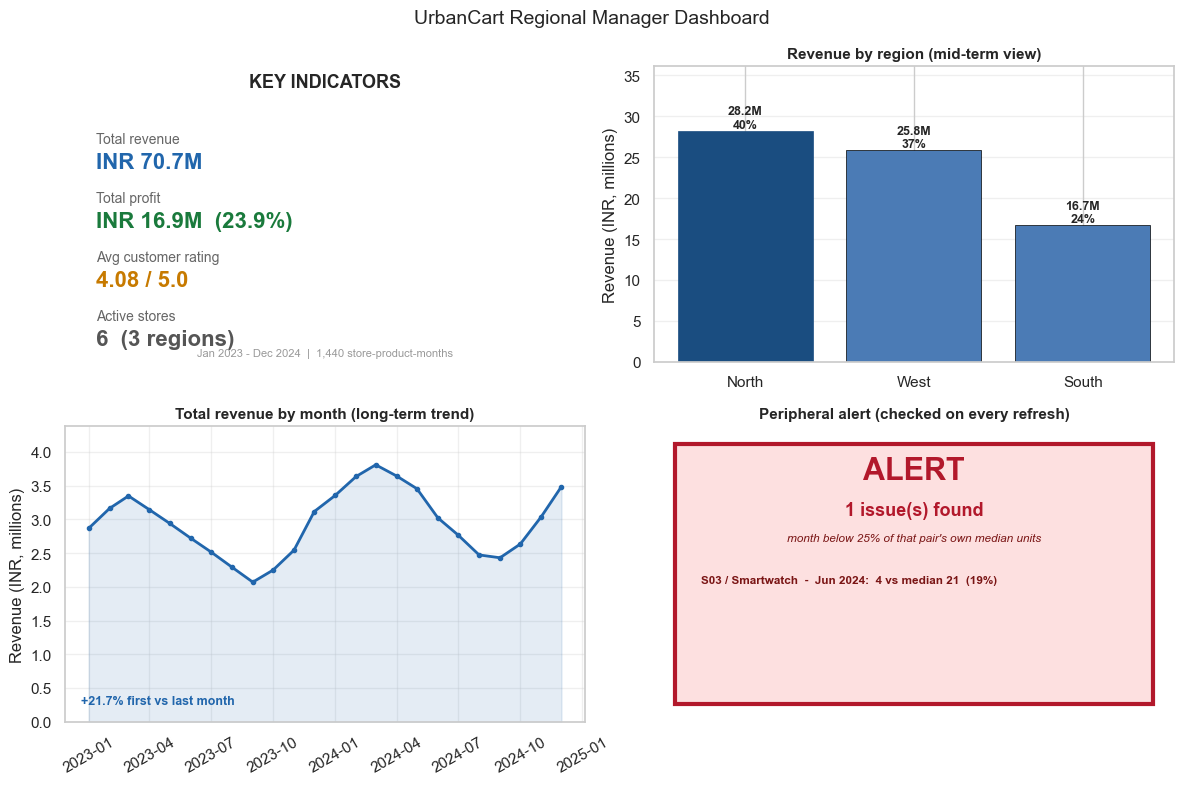

Generic alert rule scanned 60 (store, product) pairs x 24 months = 1,440 checks
Breaches found: 1
  S03 / Smartwatch, June 2024: 4 units vs median 21 (18.6%)

Note: the rule hard-codes no store and no product -- it re-derives each pair's own
median every run, so it would catch a new anomaly next month without any code change.


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# --- Panel 1: KPI summary (top-left) ---
total_revenue = sales_df.revenue.sum()
total_profit = sales_df.profit.sum()
overall_rating = sales_df.avg_rating.mean()
n_stores = sales_df.store_id.nunique()
margin = total_profit / total_revenue

ax = axes[0, 0]
ax.axis("off")
ax.text(0.5, 0.93, "KEY INDICATORS", ha="center", fontsize=13, fontweight="bold",
        transform=ax.transAxes)
kpis = [
    ("Total revenue", f"INR {total_revenue/1e6:,.1f}M", "#2166ac"),
    ("Total profit", f"INR {total_profit/1e6:,.1f}M  ({margin:.1%})", "#1a7a3c"),
    ("Avg customer rating", f"{overall_rating:.2f} / 5.0", "#c77a00"),
    ("Active stores", f"{n_stores}  ({sales_df.region.nunique()} regions)", "#555555"),
]
for i, (label, value, color) in enumerate(kpis):
    y = 0.74 - i * 0.20
    ax.text(0.06, y, label, fontsize=10, color="#666666", transform=ax.transAxes)
    ax.text(0.06, y - 0.085, value, fontsize=16, fontweight="bold", color=color,
            transform=ax.transAxes)
ax.text(0.5, 0.02, f"{sales_df.month.min():%b %Y} - {sales_df.month.max():%b %Y}  |  "
                   f"{len(sales_df):,} store-product-months",
        ha="center", fontsize=8, color="#999999", transform=ax.transAxes)

# --- Panel 2: revenue by region (top-right) ---
ax = axes[0, 1]
region_rev = sales_df.groupby("region").revenue.sum().sort_values(ascending=False)
bars = ax.bar(region_rev.index, region_rev.values / 1e6, color="#4b7bb5",
              edgecolor="black", linewidth=0.5)
bars[0].set_color("#1a4d80")
ax.set_title("Revenue by region (mid-term view)", fontsize=11, fontweight="bold")
ax.set_ylabel("Revenue (INR, millions)")
ax.grid(axis="y", alpha=0.3)
for i, v in enumerate(region_rev.values / 1e6):
    ax.text(i, v, f"{v:.1f}M\n{v / (region_rev.sum() / 1e6):.0%}", ha="center",
            va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0, (region_rev.max() / 1e6) * 1.28)

# --- Panel 3: total revenue by month, all stores (bottom-left) ---
ax = axes[1, 0]
monthly = sales_df.groupby("month").revenue.sum()
ax.plot(monthly.index, monthly.values / 1e6, color="#2166ac", linewidth=2, marker="o",
        markersize=3)
ax.fill_between(monthly.index, monthly.values / 1e6, 0, color="#2166ac", alpha=0.12)
ax.set_title("Total revenue by month (long-term trend)", fontsize=11, fontweight="bold")
ax.set_ylabel("Revenue (INR, millions)")
ax.set_ylim(0, (monthly.max() / 1e6) * 1.15)   # zero baseline: bar-like area needs honest ink
ax.tick_params(axis="x", rotation=30)
ax.grid(alpha=0.3)
growth = monthly.iloc[-1] / monthly.iloc[0] - 1
ax.annotate(f"{growth:+.1%} first vs last month",
            xy=(0.03, 0.06), xycoords="axes fraction", fontsize=9,
            fontweight="bold", color="#2166ac")

# --- Panel 4: peripheral alert panel (bottom-right) ---
# GENERIC rule -- no hard-coded store or product anywhere
med = sales_df.groupby(["store_id", "product"]).units_sold.transform("median")
breaches = sales_df[sales_df.units_sold < 0.25 * med]
n_alerts = len(breaches)

ax = axes[1, 1]
ax.axis("off")
if n_alerts:
    ax.add_patch(mpatches.Rectangle((0.04, 0.06), 0.92, 0.88, transform=ax.transAxes,
                                    facecolor="#fde0e0", edgecolor="#b2182b", linewidth=3))
    ax.text(0.5, 0.82, "ALERT", ha="center", fontsize=22, fontweight="bold",
            color="#b2182b", transform=ax.transAxes)
    ax.text(0.5, 0.70, f"{n_alerts} issue(s) found", ha="center", fontsize=13,
            fontweight="bold", color="#b2182b", transform=ax.transAxes)
    ax.text(0.5, 0.61, "month below 25% of that pair's own median units",
            ha="center", fontsize=8.5, color="#7a1515", transform=ax.transAxes,
            style="italic")
    for i, (_, r) in enumerate(breaches.sort_values("units_sold").head(4).iterrows()):
        pair_med = sales_df[(sales_df.store_id == r.store_id)
                            & (sales_df["product"] == r["product"])].units_sold.median()
        ax.text(0.09, 0.47 - i * 0.10,
                f"{r.store_id} / {r['product']}  -  {r.month:%b %Y}:  "
                f"{r.units_sold:.0f} vs median {pair_med:.0f}  "
                f"({r.units_sold / pair_med:.0%})",
                fontsize=8.5, fontweight="bold", color="#7a1515", transform=ax.transAxes)
else:
    ax.add_patch(mpatches.Rectangle((0.04, 0.06), 0.92, 0.88, transform=ax.transAxes,
                                    facecolor="#e2f5e2", edgecolor="#1a7a3c", linewidth=3))
    ax.text(0.5, 0.60, "OK", ha="center", fontsize=30, fontweight="bold",
            color="#1a7a3c", transform=ax.transAxes)
    ax.text(0.5, 0.45, "no pair below 25% of its own median", ha="center",
            fontsize=10, color="#1a7a3c", transform=ax.transAxes)
ax.set_title("Peripheral alert (checked on every refresh)", fontsize=11, fontweight="bold")

fig.suptitle("UrbanCart Regional Manager Dashboard", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Generic alert rule scanned {sales_df.groupby(['store_id','product']).ngroups} "
      f"(store, product) pairs x {sales_df.month.nunique()} months = {len(sales_df):,} checks")
print(f"Breaches found: {n_alerts}")
for _, r in breaches.iterrows():
    pm = sales_df[(sales_df.store_id == r.store_id)
                  & (sales_df["product"] == r["product"])].units_sold.median()
    print(f"  {r.store_id} / {r['product']}, {r.month:%B %Y}: "
          f"{r.units_sold:.0f} units vs median {pm:.0f} ({r.units_sold / pm:.1%})")
print("\nNote: the rule hard-codes no store and no product -- it re-derives each pair's own")
print("median every run, so it would catch a new anomaly next month without any code change.")


## Reflection

Answer briefly, referring back to the three manager complaints from the scenario intro:

1. Which single technique from this activity do you think gives UrbanCart's managers the *biggest*
   time saving, and why?
2. Which technique was hardest to implement well, and what design trade-off (from the lecture) did you
   have to think about while building it?
3. If you had to add **one more** interaction technique from the lecture that this activity didn't
   cover (e.g. geometric fisheye, magic lens, network zooming, model-based planning), where in this
   retail scenario would it actually be useful, and why?

_Your answers here._

---

### 1. Biggest time saving: the **peripheral alert panel** (Task 6, panel 4)

Not the flashiest technique, but the arithmetic is decisive. Every other tool here still requires a
manager to *decide to go looking* - open the notebook, pick a store from the dropdown, drag a
slider. The alert panel inverts that: it runs **1,440 checks (60 store-product pairs x 24 months)**
on every refresh and surfaces the single breach without anyone asking. That is complaint #3 -
"spotting a sudden dip is slow and easy to miss" - solved not by making the search faster but by
**deleting the search**.

The deeper reason it wins is that the other techniques have a *search cost that scales with the
data*, while the alert's cost to the manager is constant. The coordinated views (Task 3) are a close
second and genuinely solve complaint #2, but surveying the whole chain still costs six dropdown
selections; the alert costs zero. And unlike a human scan, the rule does not get tired at store five.

**The caveat I would put in writing, because this dataset demonstrates it directly.** An alert panel
is only as good as its threshold, and mine is closer to the edge than the clean "1 of 1,440" result
suggests. The breaching pair (S03 / Smartwatch, June 2024) sits at **18.6% of its own median**, but
the runner-up (S05 / USB-C Hub) sits at **exactly 25.0%** - it misses the cutoff by nothing at all.
Nudge the threshold from 25% to 26% and the alert count doubles from one to two, with the second
entry being ordinary Poisson noise rather than a real event. A threshold that fires on twenty rows
every morning trains managers to ignore the red box, which is worse than no alert at all because it
also consumes the attention the other three panels need. So the honest framing is: this rule works
here, but it needs to be calibrated against a known-quiet period before it ships, not chosen because
25% is a round number.

### 2. Hardest to implement well: the **focus + context drill-down** (Task 4)

Parts A and B were mechanically easy; deciding *what counts as context* was not. The naive
implementation - click the anomalous line, get a full-screen chart of S03 / Smartwatch - is what the
lecture calls **window replacement**, the most expensive tier, and it destroys the very thing that
makes the dip interpretable. In isolation, a one-month plunge to **4 units against a 21-unit median**
is genuinely ambiguous: supply shortage, seasonal collapse, product recall, or a data-entry error all
produce an identical picture.

The trade-off I had to reason about is the **Focus-Context Problem** directly: screen space is
finite, so every pixel spent on context is a pixel not spent on detail. My resolution was to spend
the context pixels on *the same product at the other five stores*, drawn as a min-max band plus an
average line. That choice is what makes the chart answer the question - the other five stores
averaged **22.8 units in June 2024 against their own 21.7-unit baseline**, i.e. no dip whatsoever -
so the event is **store-specific, not product-wide or seasonal**. A different context choice (say,
S03's other nine products) would have answered a different question, and neither is universally
"correct"; that is exactly why the decision was the hard part.

A second trade-off surfaced in **Task 5's table lens**, where I zoomed the `avg_rating` bar scale
instead of anchoring it at 0. Ratings span only **4.036 to 4.131** - a 0.095 range - so on a 0-5
scale all ten bars render identically and the column carries zero information. Zooming is defensible
*inside a table that prints the exact number beside the bar*, because the reader can always verify.
The same truncation on a standalone bar chart would manufacture differences out of noise. That the
identical technique is honest in one context and misleading in another is the part worth remembering.

### 3. One more technique I would add: a **magic lens** over the store map

**Where:** a geographic view of the store network - at 6 stores it is a nicety, at 500 it is
essential - with a draggable lens the manager moves over a cluster of stores.

**What it does:** inside the lens boundary the *encoding changes*, rather than merely magnifying.
Outside, each store is a dot sized by revenue. Inside, each store becomes a small multiple - a
sparkline of its 24-month trend, or a stacked bar of its category mix - while everything outside
keeps its original encoding.

**Why it fits this scenario specifically:** UrbanCart's stores are clustered by region (South, West,
North), and the question a regional manager actually asks is *"is this dip local to one city, or is
my whole region soft?"* The Task 3 dropdown cannot answer that - it forces one store at a time and
pushes the comparison back into the manager's head, which is complaint #2 all over again. A magic
lens answers it in a single drag, because the alternative encoding appears **in place** with the
surrounding geography intact. Concretely, it is the tool that would have let me distinguish "S03
Mumbai has a problem" from "the West region has a problem" without leaving the map.

I would choose the magic lens over a **geometric fisheye** deliberately. A fisheye distorts position
to make room for detail, and on a map that is actively harmful - it moves stores away from their true
locations, so distance and clustering, the two things a geographic view exists to show, both become
unreliable. The magic lens changes *what is drawn* while leaving *where it is drawn* alone, which is
the right trade for spatial data. **Network zooming** I would rule out for a different reason
entirely: our data has no meaningful graph structure - stores do not link to each other - so a
technique built for node-link topology would be borrowed vocabulary rather than a real fit.